# Swiss roll: layerwise goal-oriented adaptivity

Reference implementation for

> M. Hintermüller, M. Hinze and D. Korolev,
> *Layerwise goal-oriented adaptivity for neural ODEs: an optimal control perspective*,


Binary classification of two concentric spirals (Section 8.1). This is the controlled setting in which to watch the local indicators respond to layer insertion and re-optimization, and to see how the regularization parameter $\lambda$ governs the stability of the adaptive hierarchy.

All numerics live in the `lgoa` package; this notebook only chooses parameters,
runs the solver and draws the figures. The two algorithms of the paper are

* **Algorithm 1** &mdash; `lgoa.solver.solve_fixed_depth`: full-batch $H^1$-Adam
  warm start, then BFGS in $H^1$-whitened coordinates, on a fixed temporal grid;
* **Algorithm 2** &mdash; `lgoa.adaptive.run`: solve &rarr; estimate $\eta_k$
  &rarr; mark &rarr; bisect &rarr; prolongate, until the layer budget is spent.

The local indicator is the direct reconstructed residual of eq. (90): three
signed pairings, integrated by Gauss--Legendre order doubling and made
absolute only afterwards.

## 1. Install

In [1]:
# On Colab this installs the package from GitHub.
try:
    import lgoa
except ImportError:
    %pip install -q "git+https://github.com/detzer0/NODE_GOA.git"
    import lgoa

from lgoa import plots

print(lgoa.backend_report())

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
JAX 0.11.1 | backend: gpu | dtype: float32


## 2. Choose the experiment

The bulk of the hyperparameters (network size, Adam/BFGS budgets, early
stopping) lives in the YAML preset printed below &mdash; edit it only if you
want to depart from the published setup. The parameters worth varying from a
notebook are collected here.

In [14]:
# ------------------------------------------------------------
# Experimental parameters
# ------------------------------------------------------------

MARKING                = "conservative"  # or "dorfler"
DOERFLER_FRACTION      = 0.5
STATIONARITY_TOLERANCE = 1e-3
REGULARIZATION_LAMBDA  = 1e-3
INITIAL_DEPTH          = 2
MAX_DEPTH              = 12
TRANSFER_ADAM_STATE    = True

SAMPLES_PER_CLASS      = 1200
N_CANDIDATES           = 10
SEARCH_MAX_EPOCHS      = 1000
ADAM_MAX_STEPS         = 20000
BFGS_MAX_ITERATIONS    = 10000

# ------------------------------------------------------------
# Load configuration with your parameters
# ------------------------------------------------------------

cfg = lgoa.load_preset(
    "swiss_roll",
    marking=MARKING,
    dorfler_fraction=DOERFLER_FRACTION,
    stationarity_tolerance=STATIONARITY_TOLERANCE,
    reg_lambda=REGULARIZATION_LAMBDA,
    initial_depth=INITIAL_DEPTH,
    max_depth=MAX_DEPTH,
    transfer_adam_state=TRANSFER_ADAM_STATE,
    samples_per_class=SAMPLES_PER_CLASS,
    n_candidates=N_CANDIDATES,
    search_max_epochs=SEARCH_MAX_EPOCHS,
    adam_max_steps=ADAM_MAX_STEPS,
    bfgs_max_iterations=BFGS_MAX_ITERATIONS,
)

print(cfg.summary())
print("\npreset file:", lgoa.config_path("swiss_roll"))

problem                 : swiss_roll (d=4, T=2.5, 2 classes)
regularization lambda   : 0.001
stationarity tolerance  : 0.001 (kappa_s = 5)
depth budget            : K = 2 -> 12
marking rule            : conservative
indicator               : direct reconstructed residuals
state/adjoint quadrature: GL 8 -> 128 (rtol=1e-07, atol=1e-09)
control pullback       : gauss
Adam moment transfer    : on
BFGS polish             : L-BFGS-B

preset file: /usr/local/lib/python3.13/dist-packages/lgoa/configs/swiss_roll.yaml


## 3. Implementation checks

Six independent checks: the tridiagonal solve against SciPy, the hand-assembled
control and endpoint derivatives against `jax.grad`, invariance of the frozen
endpoint maps, the closed-form indicator pairing against dense quadrature, and
the equality of Dörfler refinement with one marked interval and plain
single-interval insertion.

In [15]:
lgoa.self_check()

,check,relative_error,tolerance,passed
0,JAX tridiagonal solve vs SciPy,1.571184e-16,1.000000e-09,True
1,control derivative vs jax.grad,2.422724e-16,5.000000e-08,True
2,endpoint derivative vs jax.grad,1.912119e-16,5.000000e-08,True
3,frozen endpoint maps unchanged,0.000000e+00,1.000000e-14,True
4,closed-form control pairing,6.883790e-09,2.000000e-08,True
5,Dorfler(|M|=1) == single insertion,0.000000e+00,0.000000e+00,True
6,direct state/adjoint residuals vs scalar quadr...,1.021513e-18,5.000000e-08,True
7,Gauss control residual vs scalar quadrature,1.944234e-18,5.000000e-08,True
8,endpoint-linear control residual vs scalar qua...,2.203266e-18,5.000000e-08,True


## 4. Data

Swiss roll: train (1440, 2), validation (960, 2), 2 classes


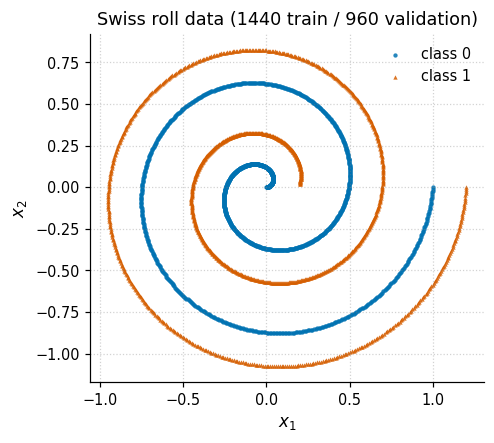

In [16]:
data = lgoa.load_dataset(cfg.problem)
print(data.summary())
plots.dataset(data);

## 5. Run the adaptive hierarchy

The endpoint maps are calibrated once on the initial partition and then frozen,
so every refinement round changes only *where* layers are inserted.

In [17]:
history = lgoa.run(cfg, data)

Calibrating endpoint maps on K = 2 ...
endpoint calibration | seed=6000 | best epoch=1000 | validation loss=0.285411 | validation accuracy=0.9188
  phase  1 | K=  2 | J=0.2819233 | val=0.229111 (acc=0.9458) | ||G||_H1=7.948e-04 (strict)
  marked 1 interval(s) [0] | indicator share = 73.2% | K: 2 -> 3
  phase  2 | K=  3 | J=0.2535834 | val=0.195144 (acc=0.9583) | ||G||_H1=7.982e-04 (strict)
  marked 1 interval(s) [2] | indicator share = 64.6% | K: 3 -> 4
  phase  3 | K=  4 | J=0.2469957 | val=0.156839 (acc=0.9740) | ||G||_H1=7.696e-04 (strict)
  marked 1 interval(s) [2] | indicator share = 42.8% | K: 4 -> 5
  phase  4 | K=  5 | J=0.2495060 | val=0.156942 (acc=0.9719) | ||G||_H1=9.420e-04 (strict)
  marked 1 interval(s) [2] | indicator share = 27.3% | K: 5 -> 6
  phase  5 | K=  6 | J=0.2452037 | val=0.154879 (acc=0.9729) | ||G||_H1=9.465e-04 (strict)
  marked 1 interval(s) [1] | indicator share = 35.5% | K: 6 -> 7
  phase  6 | K=  7 | J=0.1826399 | val=0.104768 (acc=0.9927) | ||G||_H1=8.

In [18]:
print(history.summary())

columns = [
    "phase", "depth", "objective", "data_loss", "validation_loss",
    "validation_accuracy", "stationarity_norm", "stationarity_status",
    "marked_intervals", "marked_indicator_share", "adam_steps", "bfgs_iterations",
]
history.phase_table[columns].round(6)

final depth            : K = 12 after 10 refinement rounds
final objective        : 0.12210923
final validation loss  : 0.057461  (accuracy 0.9948)
final ||G||_H1         : 7.310e-04
stationary phases      : 100%
optimizer work         : 24,900 Adam steps, 2,143 BFGS iterations
wall time              : 71.8 s


,phase,depth,objective,data_loss,validation_loss,validation_accuracy,stationarity_norm,stationarity_status,marked_intervals,marked_indicator_share,adam_steps,bfgs_iterations
0,1,2,0.281923,0.203728,0.229111,0.945833,0.000795,strict,0,0.731878,900,59
1,2,3,0.253583,0.169205,0.195144,0.958333,0.000798,strict,2,0.646122,4600,136
2,3,4,0.246996,0.136334,0.156839,0.973958,0.000770,strict,2,0.428172,5400,239
3,4,5,0.249506,0.139516,0.156942,0.971875,0.000942,strict,2,0.272876,2000,62
4,5,6,0.245204,0.138137,0.154879,0.972917,0.000946,strict,1,0.354767,500,43
5,6,7,0.182640,0.095785,0.104768,0.992708,0.000857,strict,6,0.316294,4400,160
6,7,8,0.146386,0.060331,0.076097,0.993750,0.000966,strict,5,0.235232,2000,499
7,8,9,0.140723,0.056149,0.073344,0.993750,0.000949,strict,7,0.259544,500,122
8,9,10,0.135668,0.053198,0.070178,0.993750,0.000927,strict,0,0.170073,500,94
9,10,11,0.133069,0.054388,0.064796,0.991667,0.000950,strict,2,0.155740,3600,172


## 6. Figures

### 6.1 Quantities along the hierarchy

Stationarity measure against $\varepsilon_{\mathrm{stat}}$, the optimized
objective, both losses, and accuracy &mdash; each against the depth $K$.

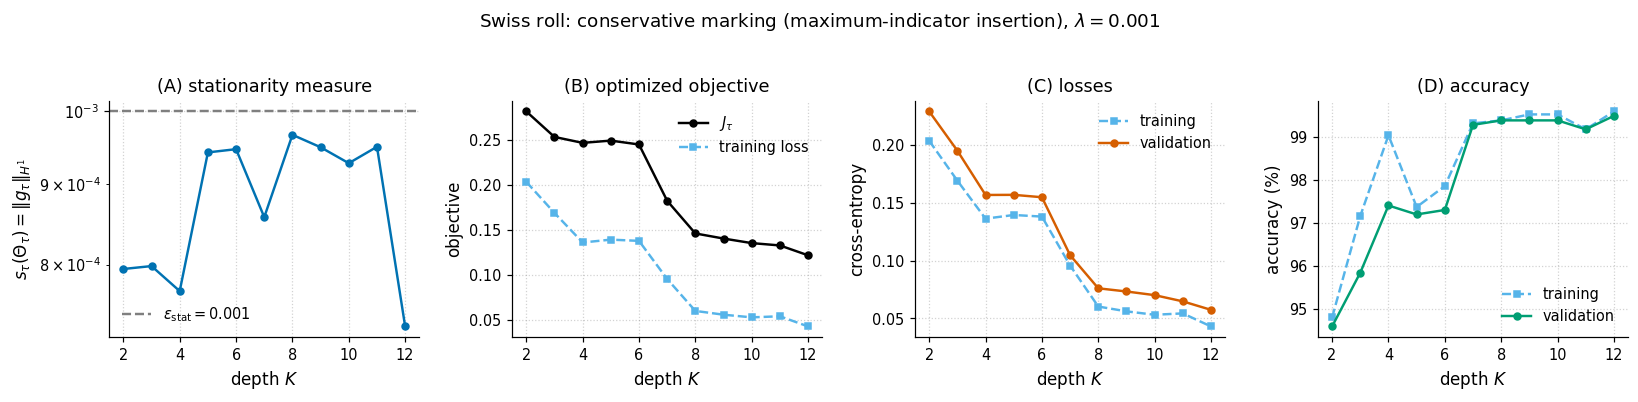

In [19]:
plots.learning_curves(history);

### 6.2 The adaptive grids

One row per phase, with the nodes marked; the triangles show where the next
layers are about to be inserted.

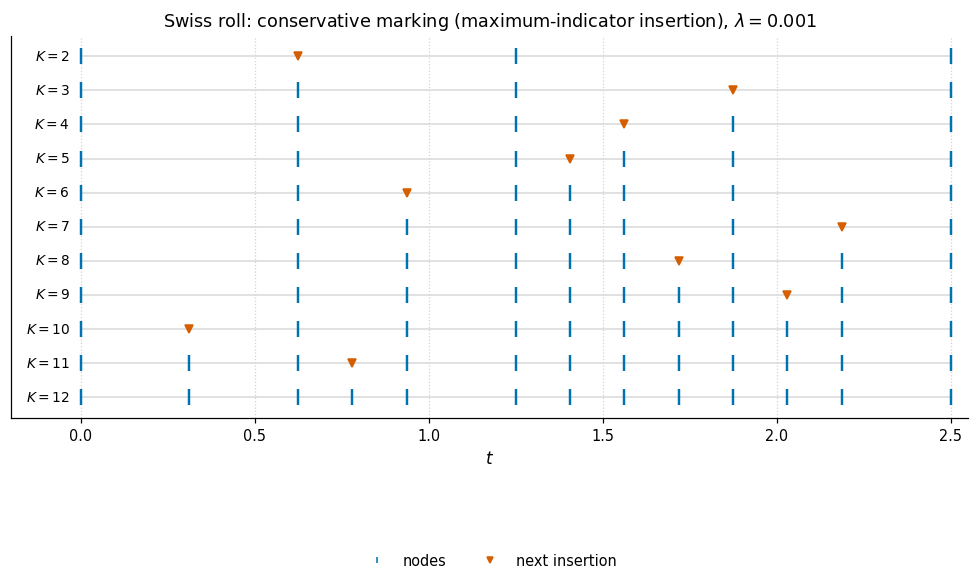

In [20]:
plots.grid_history(history);

### 6.3 Refinement events

Local indicators $\eta_k$ before insertion, immediately after insertion, and
after re-optimization. Red bars are the marked parents on the left and their
children in the other two columns. A children-to-parent ratio below one means
re-optimization removed indicator mass from the refined region.

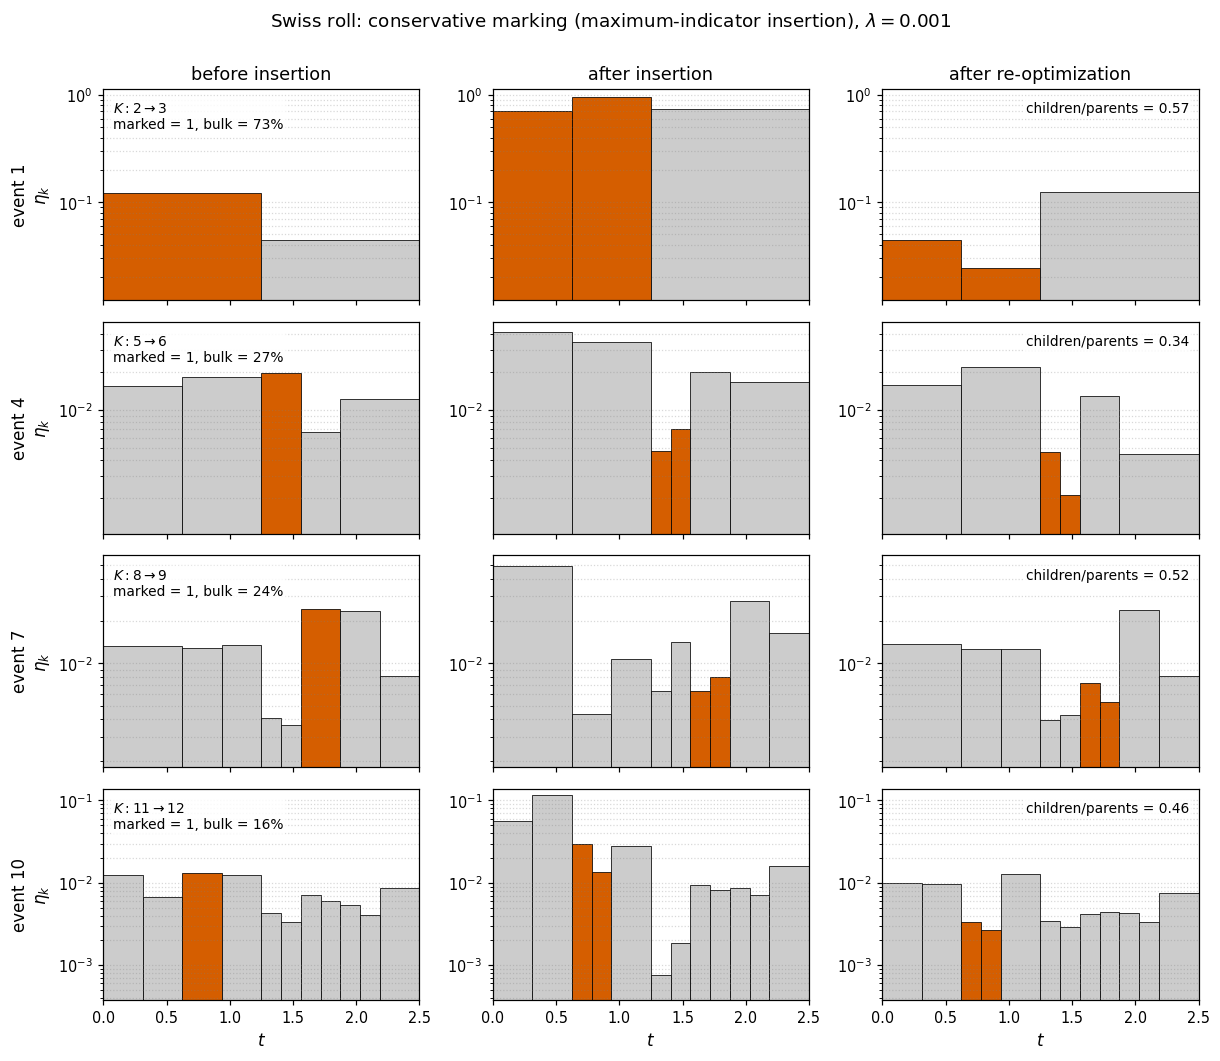

In [21]:
plots.refinement_events(history, n_events=4);

### 6.4 Indicator components

How the adjoint, control and state contributions to $\eta_K$ evolve with depth,
and the local distribution on the final grid.

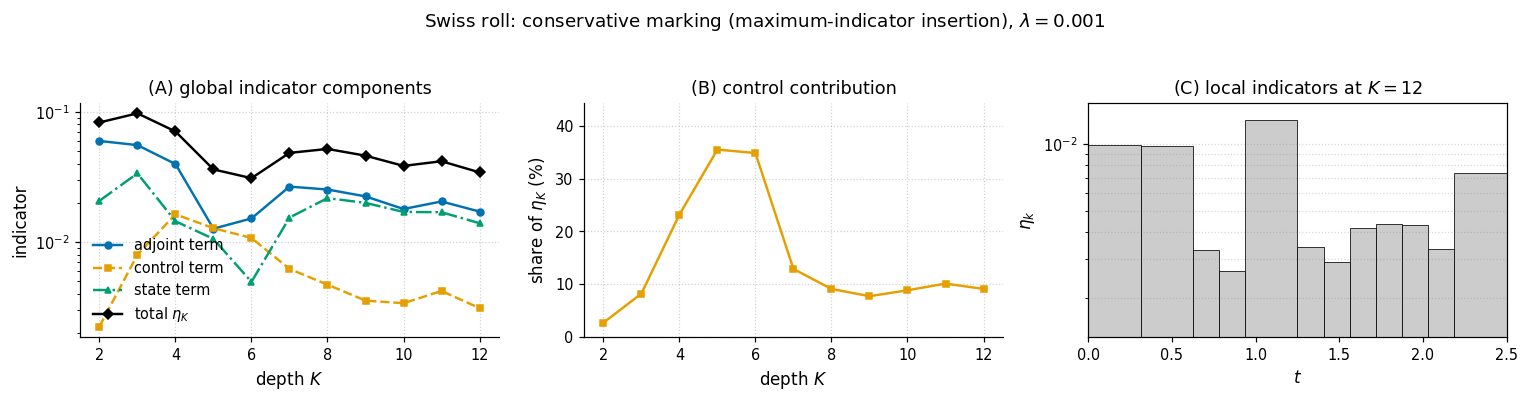

In [22]:
plots.indicator_components(history);

### 6.5 State, control and adjoint

The triplet on the final grid. Weak regularization gives visibly more
oscillatory trajectories, i.e. a richer feature transformation.

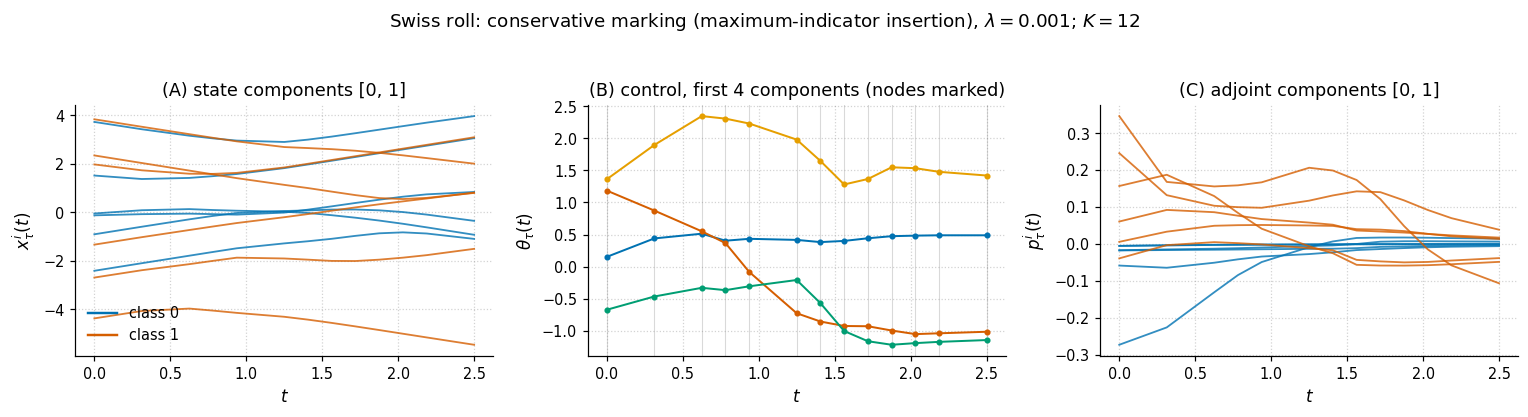

In [23]:
plots.trajectories(history, data);

### 6.6 Prediction of the trained neural ODE

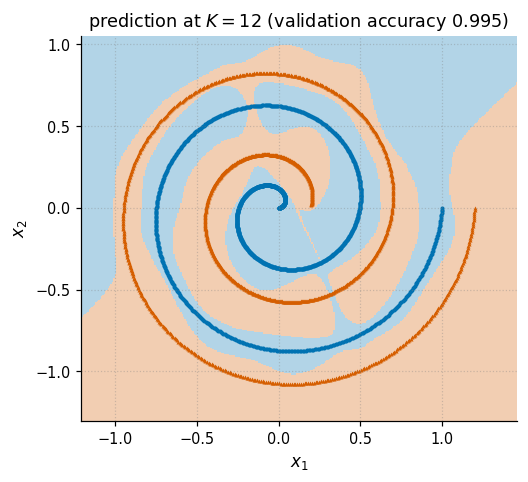

In [24]:
plots.decision_boundary(history, data);

## 7. Export

Figures as PDF and PNG, tables as CSV. On Colab the files appear in the file
browser on the left; the last line zips them for download.

In [25]:
figure_paths = plots.save_all(history, data, "figures")
table_paths = history.to_csv("results")
print(f"{len(figure_paths)} figure files, {len(table_paths)} tables")

# Colab only: uncomment to download everything as a single archive.
# import shutil; from google.colab import files
# shutil.make_archive("lgoa_output", "zip", ".", "figures")
# files.download("lgoa_output.zip")

14 figure files, 4 tables


## 8. Conservative against Dörfler marking

Re-running from the same calibration keeps the comparison paired: identical
data, identical endpoint maps, identical initial control and the same layer
budget &mdash; only the marked set differs. Conservative marking inserts one
layer per round and so re-optimizes after every single insertion; Dörfler
marking inserts a whole bulk at once, which buys fewer rounds of global
re-optimization at the price of less selective placement.

```python
import pandas as pd

calibration = history.calibration          # reuse the frozen endpoint maps
runs = {"conservative": cfg.with_overrides(marking="conservative")}
for fraction in (0.25, 0.5, 0.75):
    runs[f"dorfler {fraction}"] = cfg.with_overrides(
        marking="dorfler", dorfler_fraction=fraction
    )

results = {
    name: lgoa.run(config, data, calibration, progress=False)
    for name, config in runs.items()
}
pd.DataFrame([r.totals() for r in results.values()], index=list(results))
```

Table 1 of the paper reports that $\lambda = 10^{-3}$ is the most robust compromise: stronger regularization stabilizes the hierarchy but limits expressivity, while $\lambda \le 10^{-5}$ makes stationarity progressively harder to reach. Re-run section 2 with `REGULARIZATION_LAMBDA = 1e-2` or `1e-6` to see both failure modes.